### SIMULACIONES DE MONTE CARLO

#### 01. IMPORTACIÓN DE LIBRERÍAS

Se importan numpy para la parte matemática de las simulaciones, y matplotlib para graficar las simulaciones.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

#### 02. DATOS FIJOS DE LAS SIMULACIONES

Se determinan los siguientes datos para las simulaciones:
* T: Cantidad de periodos de madurez de la opción. 5 años según la descripción tecnica del reto.
* n_trayectories: Cantidad de trayectorias que se simularán con Monte Carlo. 100.000 trayectorias según la descripción técnica del reto.
* n_times: Cantidad de intervalos de tiempo donde se volverá a calcular el precio del activo hasta alcanzar la madurez. 21 intervalos, 20 según la descripción técnica del reto y el periodo inicial.
* n_times_1: Cantidad de intervalos de tiempo donde se volverá a calcular el precio del activo hasta alcanzar los 5 periodos donde la parte estocástica del movimiento browniano geométrico será la misma para todas las trayectorias. 5 intervalos según la descripción técnica del reto y el periodo inicial.
* n_times_2: Cantidad de intervalos de tiempo donde se volverá a calcular el precio del activo hasta alcanzar los periodos restantes hasta alcanzar la madurez, donde la parte estocástica del movimiento browniano geométrico no será la misma para todas las trayectorias. 15 intervalos, la diferencia entre n_times y n_times_1.
* S_0: Precio de los activos en el periodo inicial. Lista de tantos precios como activos.
* mu: Tasa de los activos sin riesgo. Lista de tantas tasas como activos. 0.01 para todos los activos según se indica en la descripción técnica del reto.
* sigma: Volatilidad media del mercado de cada activo. Lista de tantas volatilidades medias como activos.
* rho: Matriz de correlaciones de los activos. 
* seed: Semilla de aleatoriedad.

In [2]:
T = 5
n_trayectories = 100000 
n_times = 21
n_times_1 = 6
n_times_2 = (n_times - n_times_1)
S_0 = [1,1,1] #ESTO CAMBIARÁ
mu = np.array([0.01, 0.01, 0.01])
sigma = np.array([0.2, 0.25, 0.3]) #ESTO CAMBIARÁ
rho = np.array([[1.00, 0.60, 0.30], [0.60, 1.00, 0.40], [0.30, 0.40, 1.00]]) #ESTO CAMBIARÁ
seed = 42

#### 03. CORRELACIÓN DE LA ESTOCASTIDAD DEL MOVIMIENTO BROWNIANO GEOMÉTRICO

Se aplica la descomposición de Cholesky a la matriz de correlaciones de los activos para conseguir la matriz triangular inferior. Después se multiplica con la matriz de valores aleatorios que compone la estocasticidad del movimiento browniano geométrico de los primeros 5 intervalos temporales y posteriormente de los 15 periodos temporales posteriores para conseguir estocasticidad coherente a las correlaciones de los activos.

In [3]:
A = np.linalg.cholesky(rho)
At = A.T
rng = np.random.default_rng(seed = seed)
X1 = rng.standard_normal((1, n_times_1-1, (len(S_0))))
X1_cor = X1 @ At
X2 = rng.standard_normal((n_trayectories, n_times_2, len(S_0)))
X2_cor = X2 @ At

#### 04. MOVIMIENTO BROWNIANO GEOMÉTRICO

Se crea la matriz de los datos sintéticos con tantas capas como trayectorias, tantas filas como intervalos de tiempos, y tantas columnas como activos, donde los precios de cada activo son los mismos para todas las trayectorias en los primeros 5 periodos temporales y los precios durante los 15 intervalos temporales restantes siguen un movimiento browniano geométrico en todas las trayectorias para todos los activos.

In [4]:
S1 = np.empty((n_trayectories, n_times_1, len(S_0)))
S1[:, 0, :] = np.array(S_0)
delta_t = T/(n_times - 1)
S1[:, 1:, :] = np.exp(((mu-(sigma**2/2))*delta_t)+(sigma*np.sqrt(delta_t)*X1_cor))
S2 = np.empty((n_trayectories, n_times, len(S_0)))
S2[:, :n_times_1, :] = S1
S2[:, n_times_1: , :] = np.exp(((mu-(sigma**2/2))*delta_t)+(sigma*np.sqrt(delta_t)*X2_cor))
MC = np.cumprod(S2, axis = 1)

#### 06.MEDIA GEOMETRICA
A partir de las trayectorias simuladas mediante Monte Carlo se calcula la media geométrica de cada activo para cada trayectoria. Para ello, se utiliza una formulación equivalente basada en logaritmos, que resulta más eficiente y estable numéricamente que el cálculo directo del producto de todos los precios.

Posteriormente se obtiene el payoff de la opción. El producto considera la suma de las medias geométricas de los tres activos y la compara con el precio de ejercicio $E = 3$. Si dicha diferencia es positiva, el payoff toma ese valor; en caso contrario, el payoff es igual a cero.

Finalmente, se almacenan por separado las medias geométricas de cada activo y se calcula el payoff correspondiente a cada una de las trayectorias simuladas.

In [8]:
E = 3 
media_geometrica = np.exp(
    np.mean(
        np.log(MC / np.array(S_0)),
        axis=1
    )
)
G1 = media_geometrica[:,0]
G2 = media_geometrica[:,1]
G3 = media_geometrica[:,2]
payoff = np.maximum(
    media_geometrica.sum(axis=1) - E,
    0
)
media_geometrica

array([[1.08435498, 0.97864421, 0.98935574],
       [0.86443977, 0.66531243, 0.88870371],
       [1.15166008, 0.79700633, 0.7684189 ],
       ...,
       [0.85307607, 0.63192327, 0.94092167],
       [1.34034398, 0.85568386, 1.12899883],
       [1.10092591, 0.62533013, 0.56590945]], shape=(100000, 3))

#### 05. VISUALIZACIÓN DE LAS SIMULACIONES

Se generán tantos gráficos como activos con la trayectoria de sus precios en los 20 intervalos temporales.

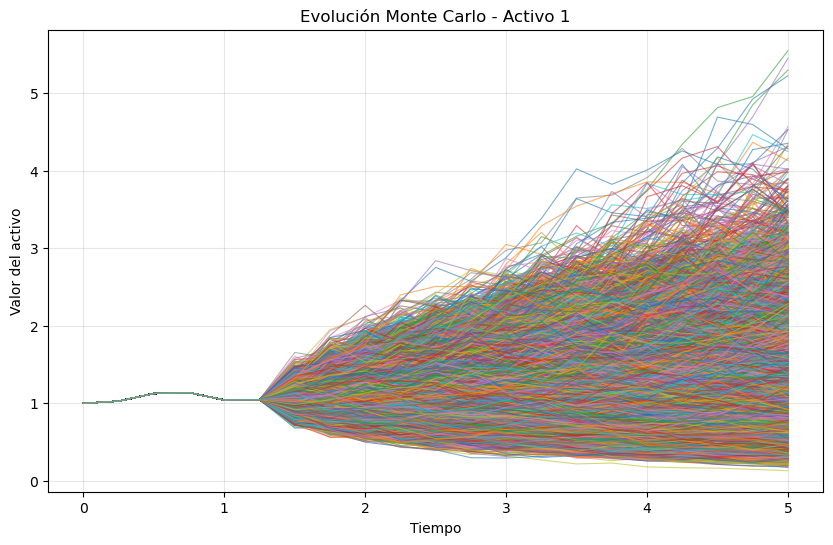

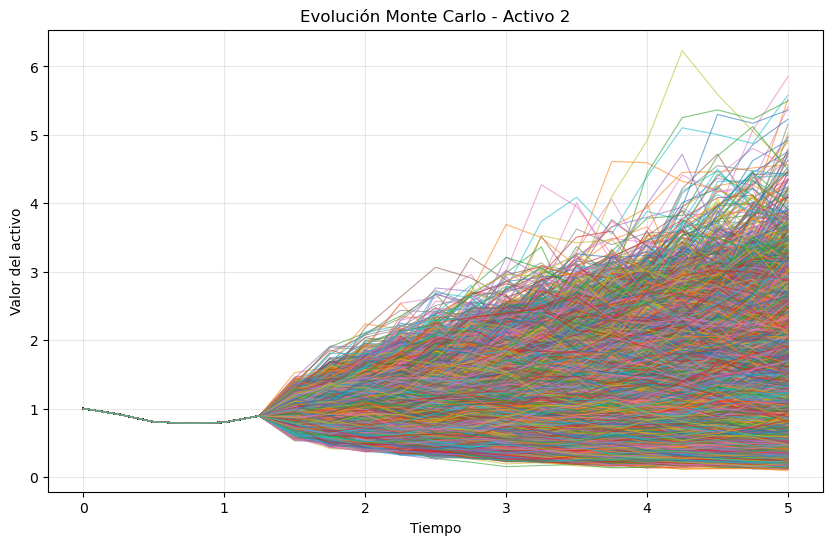

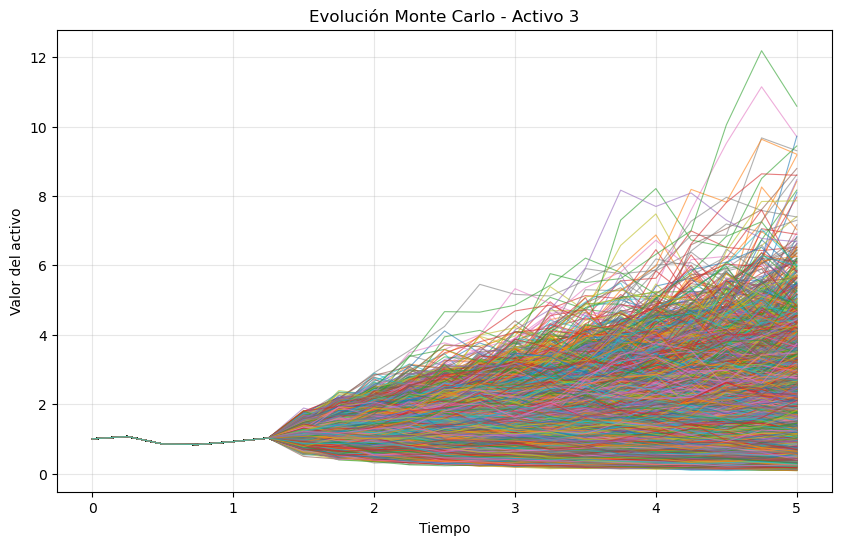

In [6]:
tiempo = np.linspace(0, T, n_times)
for activo in range(len(S_0)):
    plt.figure(figsize=(10, 6))
    for trayectoria in range(n_trayectories):
        plt.plot(
            tiempo,
            MC[trayectoria, :, activo],
            alpha=0.6,
            linewidth=0.8
        )
    plt.title(f"Evolución Monte Carlo - Activo {activo + 1}")
    plt.xlabel("Tiempo")
    plt.ylabel("Valor del activo")
    plt.grid(alpha=0.3)
    plt.show()